In [1]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split


In [2]:
best_xgb = joblib.load("../models/best_xgboost.joblib")

df = pd.read_csv("../data/cleaned/cleaned_credit_default.csv")

y = df["SeriousDlqin2yrs"]
X = df.drop(columns=["SeriousDlqin2yrs"])

In [3]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
encoder = joblib.load("../models/agegroup_encoder.joblib")

categorical_cols = ["AgeGroup"]
numeric_cols = X_train.columns.difference(categorical_cols).tolist()

X_train_cat = encoder.transform(X_train[categorical_cols])
X_test_cat = encoder.transform(X_test[categorical_cols])

X_train_num = X_train[numeric_cols].to_numpy()
X_test_num = X_test[numeric_cols].to_numpy()

X_train_final = np.hstack([X_train_num, X_train_cat])
X_test_final = np.hstack([X_test_num, X_test_cat])

In [4]:
feature_names = (
        numeric_cols +
        list(encoder.get_feature_names_out(categorical_cols))
)

print("Number of features:", len(feature_names))
print(feature_names)

Number of features: 24
['DebtRatio', 'Has90DaysLate', 'HasAnyDelinquency', 'HighUtilization', 'IncomeMissing', 'IncomePerCreditLine', 'MonthlyIncome', 'NumberOfDependents', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'RevolvingUtilizationOfUnsecuredLines', 'TotalCreditLines', 'TotalDelinquencies', 'age', 'AgeGroup_21-30', 'AgeGroup_31-40', 'AgeGroup_41-50', 'AgeGroup_51-60', 'AgeGroup_61-70', 'AgeGroup_71-80', 'AgeGroup_81+']


In [5]:
import shap

explainer = shap.TreeExplainer(best_xgb)

shap_values = explainer.shap_values(X_test_final)

print("SHAP shape:", shap_values.shape)

SHAP shape: (29804, 24)


In [6]:
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "MeanAbsSHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "MeanAbsSHAP",
    ascending=False
)

shap_importance

,Feature,MeanAbsSHAP
13,RevolvingUtilizationOfUnsecuredLines,0.728550
2,HasAnyDelinquency,0.495746
15,TotalDelinquencies,0.242289
16,age,0.227702
5,IncomePerCreditLine,0.107471
0,DebtRatio,0.080094
1,Has90DaysLate,0.077899
12,NumberRealEstateLoansOrLines,0.074619
14,TotalCreditLines,0.064305
8,NumberOfOpenCreditLinesAndLoans,0.063838


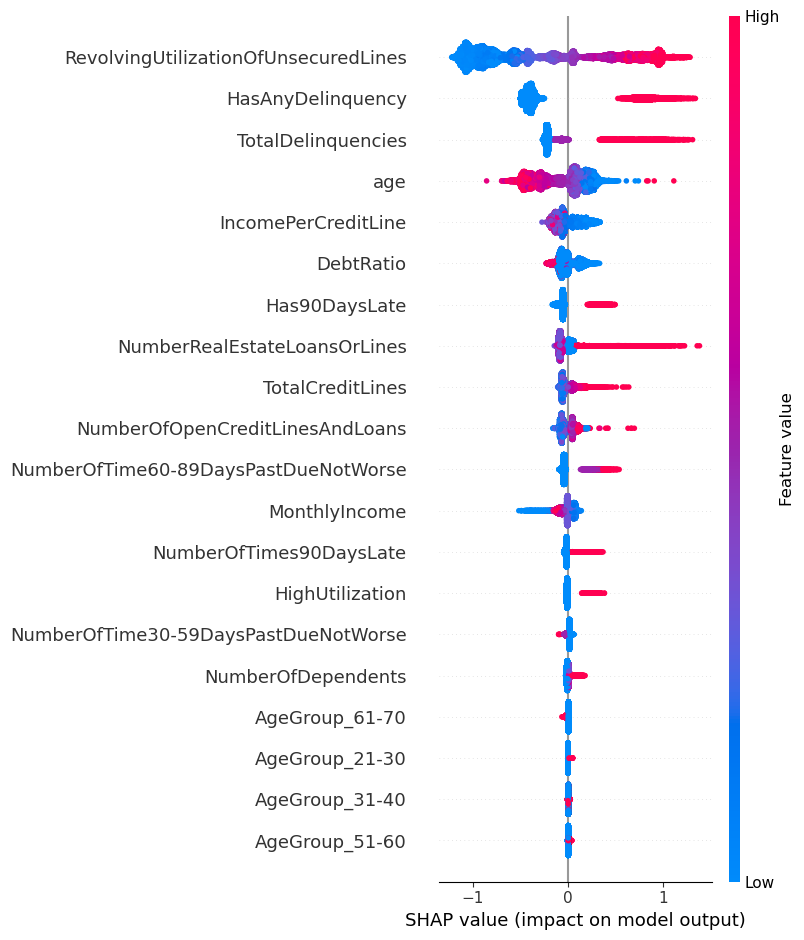

In [7]:
shap.summary_plot(
    shap_values,
    X_test_final,
    feature_names=feature_names
)

### Individual Prediction Explanation

In [8]:
sample_idx = 0

sample = X_test_final[sample_idx:sample_idx + 1]
sample_shap = shap_values[sample_idx]

shap_exp = shap.Explanation(
    values=sample_shap,
    base_values=explainer.expected_value,
    data=sample[0],
    feature_names=feature_names
)

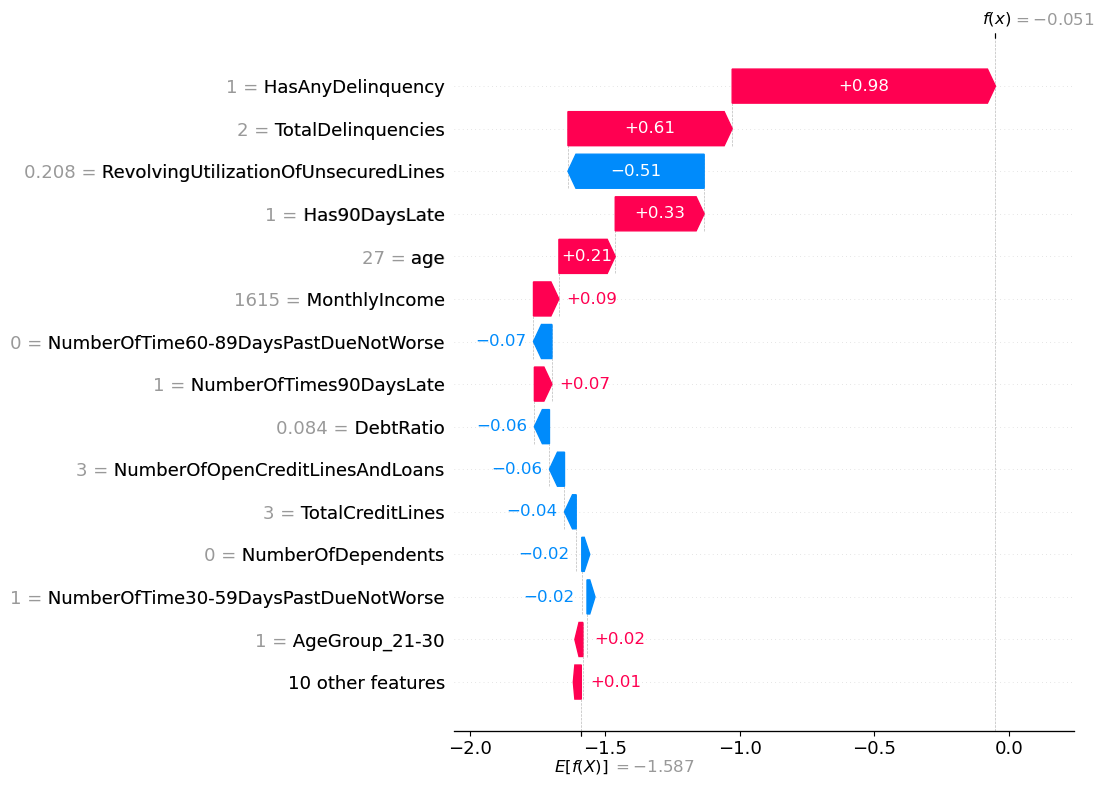

In [9]:
shap.plots.waterfall(shap_exp, max_display=15)

## SHAP Dependence Plot


### 1. RevolvingUtilizationOfUnsecuredLines


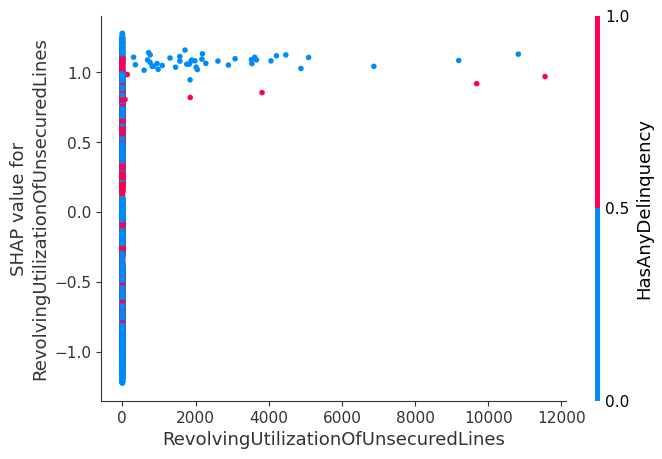

In [10]:
shap.dependence_plot(
    "RevolvingUtilizationOfUnsecuredLines",
    shap_values,
    X_test_final,
    feature_names=feature_names
)

### SHAP Dependence Plot — RevolvingUtilizationOfUnsecuredLines

1. **X-axis:** Actual value of `RevolvingUtilizationOfUnsecuredLines`.
2. **Y-axis:** SHAP value, showing the feature's contribution to the model prediction.
3. **SHAP > 0:** Pushes the prediction toward **default (class 1)**.
4. **SHAP < 0:** Pushes the prediction toward **no default (class 0)**.
5. Most observations are concentrated near **0** on the X-axis.
6. Very high utilization values generally have **positive SHAP values**, pushing the model toward default.
7. The color represents `HasAnyDelinquency`, showing its interaction with this feature.
8. Overall, the plot shows how different utilization values influence the model's default prediction.


### 2. HasAnyDelinquency


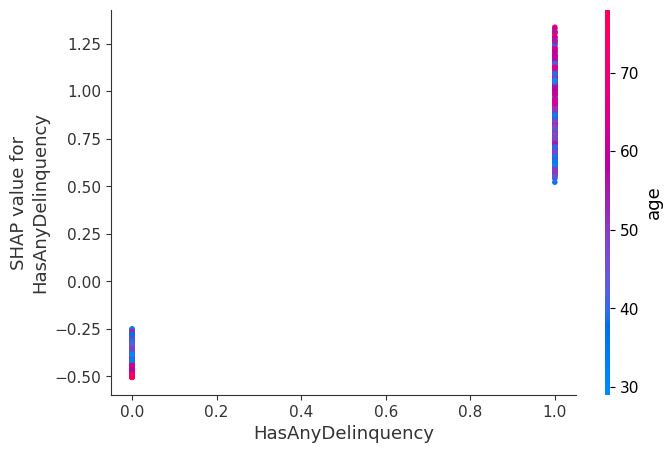

In [11]:
shap.dependence_plot(
    "HasAnyDelinquency",
    shap_values,
    X_test_final,
    feature_names=feature_names
)

# SHAP Findings Summary

This section consolidates the key findings from the SHAP analysis and completes the interpretation of the XGBoost model.

---

## 1. Global Feature Importance

The most influential features were identified using **mean absolute SHAP values**.

| Rank | Feature | Mean Absolute SHAP |
|---:|---|---:|
| 1 | `RevolvingUtilizationOfUnsecuredLines` | 0.728550 |
| 2 | `HasAnyDelinquency` | 0.495746 |
| 3 | `TotalDelinquencies` | 0.242289 |
| 4 | `age` | 0.227702 |
| 5 | `IncomePerCreditLine` | 0.107471 |
| 6 | `DebtRatio` | 0.080094 |
| 7 | `Has90DaysLate` | 0.077899 |
| 8 | `NumberRealEstateLoansOrLines` | 0.074619 |

### Key Observation

`RevolvingUtilizationOfUnsecuredLines` is the most influential feature, followed by the engineered delinquency features `HasAnyDelinquency` and `TotalDelinquencies`.

---

## 2. Main Model Behavior

### Utilization

Higher values of `RevolvingUtilizationOfUnsecuredLines` generally push the model toward **default (class 1)**, with particularly strong effects at extreme values.

### Delinquency

`HasAnyDelinquency`, `TotalDelinquencies`, and individual late-payment features generally push the model toward **default** when their values indicate delinquency.

### Age

`age` has a meaningful but nonlinear contribution. Its effect is not simply:

> Older age = lower risk

The model's contribution depends on the specific value and its interaction with other features.

### Engineered Features

Two engineered features are particularly important:

- `HasAnyDelinquency`
- `TotalDelinquencies`

They rank **#2 and #3** in global SHAP importance, showing that the engineered delinquency information provides substantial predictive signal.

`IncomePerCreditLine` also provides meaningful additional information to the model.

---

## 3. Individual Prediction Analysis

The SHAP waterfall plot was used to explain the prediction for one example customer.

### Features pushing toward default

| Feature | SHAP Contribution |
|---|---:|
| `HasAnyDelinquency = 1` | **+0.98** |
| `TotalDelinquencies = 2` | **+0.61** |
| `Has90DaysLate = 1` | **+0.33** |
| `age = 27` | **+0.21** |

These features increased the model's output toward **default (class 1)**.

### Features pushing away from default

| Feature | SHAP Contribution |
|---|---:|
| `RevolvingUtilizationOfUnsecuredLines = 0.208` | **−0.51** |
| `DebtRatio = 0.084` | **−0.06** |

These features moved the model's output toward **no default (class 0)** for this particular customer.

This demonstrates that SHAP can explain **individual predictions**, not just overall feature importance.

---

## 4. Final Conclusion

### SHAP Interpretation — Key Findings

SHAP analysis was used to interpret the XGBoost model both **globally** and at the **individual prediction level**.

The most influential feature was `RevolvingUtilizationOfUnsecuredLines`, followed by `HasAnyDelinquency` and `TotalDelinquencies`.

Higher revolving utilization generally increased the model's predicted default tendency, particularly at extreme values. Customers with delinquency-related features generally received positive SHAP contributions, pushing the model toward default.

The engineered features `HasAnyDelinquency` and `TotalDelinquencies` captured important predictive information. `IncomePerCreditLine` and `age` also provided additional model signal.

The individual SHAP waterfall analysis demonstrated how multiple features can simultaneously increase or decrease the model output for a particular customer.

> **Important:** SHAP explains the behavior of the trained model. SHAP values describe model associations and should **not** be interpreted as evidence of causal relationships.
